# Scene Classification Using VGG16 Feature Extraction,SVM acc 90%
Image classification is one of the most important tasks in Computer Vision. In this project, we classify natural scenes such as mountains, streets, forests, and oceans using a hybrid approach that combines deep learning feature extraction with a classical machine learning classifier.

Instead of training a deep neural network from scratch, we use a pre-trained convolutional neural network to extract meaningful image features and then train a classifier on those features.

# 1. Method Overview
The pipeline used in this project consists of the following steps:

1️⃣ Load images from the dataset

2️⃣ Extract deep features using a pretrained CNN

3️⃣ Normalize the extracted features

4️⃣ Train a machine learning classifier

5️⃣ Evaluate the model performance

This approach is commonly known as deep feature extraction.

# 2. Feature Extraction with VGG16
For feature extraction, we use VGG16, a well-known convolutional neural network trained on the ImageNet dataset.

Key settings used:

weights = "imagenet" → use pretrained weights

include_top = False → remove the classification layers

pooling = "avg" → apply global average pooling

This configuration allows the network to act as a feature extractor, converting each image into a numerical feature vector that represents high-level visual patterns.

Each image is resized to

2026-04-28 02:28:51.681935: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777343331.966324      16 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777343332.056799      16 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777343332.731756      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777343332.731820      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777343332.731824      16 computation_placer.cc:177] computation placer alr

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Loading and extracting features...


100%|██████████| 6/6 [16:28<00:00, 164.78s/it]


Training SVM on VGG16 features...
Accuracy: 0.908

Classification Report:
               precision    recall  f1-score   support

    mountain       0.86      0.86      0.86       525
      street       0.93      0.92      0.93       501
     glacier       0.85      0.83      0.84       553
   buildings       0.91      0.90      0.91       437
         sea       0.92      0.96      0.94       510
      forest       0.99      0.98      0.99       474

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000



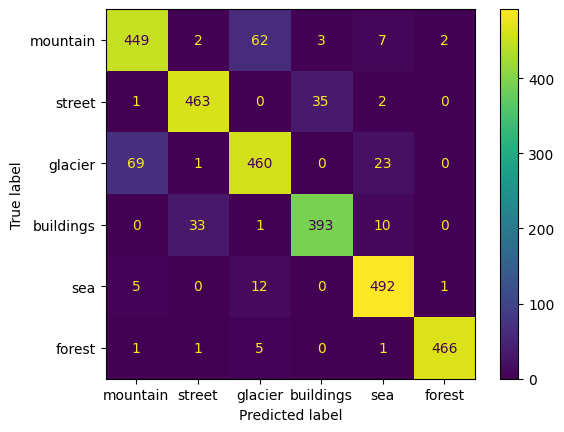

In [1]:
import os
import numpy as np
import cv2
from tqdm import tqdm
from sklearn import svm, metrics
from sklearn.preprocessing import StandardScaler
from sklearn.utils import shuffle
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array, load_img

class_name = ['mountain', 'street', 'glacier', 'buildings', 'sea', 'forest']
class_name_labels = {name: i for i, name in enumerate(class_name)}

vgg_model = VGG16(weights='imagenet', include_top=False, pooling='avg')  # feature extractor

def extract_vgg_features(img_path):
    img = load_img(img_path, target_size=(224, 224))
    img = img_to_array(img)
    img = np.expand_dims(img, axis=0)
    img = preprocess_input(img)
    features = vgg_model.predict(img, verbose=0)
    return features.flatten()

def load_data_vgg():
    datasets_paths = [
        r'/kaggle/input/datasets/shanmukh05/ml-hackathon/seg_train/seg_train',
        r'/kaggle/input/datasets/shanmukh05/ml-hackathon/seg_test/seg_test'
    ]
    output = []

    for dataset_path in datasets_paths:
        features_list = []
        labels_list = []

        for folder in tqdm(os.listdir(dataset_path)):
            if folder not in class_name_labels:
                continue
            label = class_name_labels[folder]
            folder_path = os.path.join(dataset_path, folder)

            for file in os.listdir(folder_path):
                img_path = os.path.join(folder_path, file)
                try:
                    feats = extract_vgg_features(img_path)
                    features_list.append(feats)
                    labels_list.append(label)
                except:
                    continue

        features_array = np.array(features_list)
        labels_array = np.array(labels_list)
        output.append((features_array, labels_array))
    return output

print("Loading and extracting features...")
(train_features, train_labels), (test_features, test_labels) = load_data_vgg()

train_features, train_labels = shuffle(train_features, train_labels, random_state=42)

scaler = StandardScaler()
train_features = scaler.fit_transform(train_features)
test_features = scaler.transform(test_features)

print("Training SVM on VGG16 features...")
clf = svm.SVC(kernel='rbf', C=50, gamma=0.001)
clf.fit(train_features, train_labels)

y_pred = clf.predict(test_features)
accuracy = metrics.accuracy_score(test_labels, y_pred)
print(f"Accuracy: {accuracy:.3f}\n")
print("Classification Report:\n", metrics.classification_report(test_labels, y_pred, target_names=class_name))

disp = metrics.ConfusionMatrixDisplay.from_predictions(test_labels, y_pred, display_labels=class_name)
import matplotlib.pyplot as plt

plt.show()


In [2]:
import joblib

# Save SVM model
joblib.dump(clf, "svm_vgg16_model.pkl")

# Save scaler
joblib.dump(scaler, "vgg16_scaler.pkl")

# Save label mapping
joblib.dump(class_name_labels, "labels.pkl")

print("Model, scaler, and labels saved successfully!")


Model, scaler, and labels saved successfully!
